# 02a — Probability & Inference Analyst: Pemodelan Probabilitas (Tahap 2)

**Peran:** Probability & Inference Analyst *(peluang bersyarat, distribusi teoretis, selang kepercayaan, dan uji hipotesis)*  
**Dikerjakan oleh:** Rafli Adriana Saputra (257006111004)  
**Kelompok / Tema:** Kelompok 12 — Tema B (Kualitas Udara & Mobilitas Perkotaan)  

### Ruang Lingkup Analisis Tahap 2
Tahap ini berfokus pada kuantifikasi ketidakpastian dan pemodelan sebaran data menggunakan pendekatan probabilitas empiris maupun teoretis melalui tiga tahapan utama:

| Bagian | Fokus Analisis | Acuan Panduan |
| :--- | :--- | :--- |
| **A** | Perhitungan peluang empiris (minimal 3 kejadian) dan peluang bersyarat (minimal 2 kejadian) | Checklist 2a |
| **B** | Uji kecocokan variabel kontinu `Indeks_PM25` terhadap Distribusi Normal serta simulasi peluang 2 skenario batas | Checklist 2b |
| **C** | Pemodelan variabel biner `Status_Udara` menggunakan Distribusi Binomial ($n = 20$) untuk nilai $P(X = k)$ dan $P(X \ge k)$ | Checklist 2c |

In [2]:
# ============ SETUP (jalankan sel ini PERTAMA) ============
import os, sys, subprocess
GITHUB_USER = "Tur-ai"
GITHUB_REPO = "udara-mobilitas-statsprob"
BRANCH = "main"

if "google.colab" in sys.modules:
    PROYEK = "/content/proyek"
    if not os.path.exists(PROYEK):
        token = ""
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN") + "@"
        except Exception:
            pass
        url = f"https://{token}github.com/{GITHUB_USER}/{GITHUB_REPO}.git"
        r = subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, url, PROYEK],
                           capture_output=True, text=True)
        if r.returncode != 0:
            pesan = (r.stderr or "").replace(token.rstrip("@"), "***") if token else (r.stderr or "")
            raise RuntimeError("Gagal clone repo. Cek GITHUB_USER/GITHUB_REPO, atau lihat bagian "
                               "'Troubleshooting' di docs/02_panduan_github_colab.md\n" + pesan)
    else:
        subprocess.run(["git", "-C", PROYEK, "pull"], capture_output=True)
    os.chdir(PROYEK)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
from src.helpers import *

sns.set_theme(style="whitegrid", font_scale=1.0)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("Setup selesai. Folder kerja:", os.getcwd())

Setup selesai. Folder kerja: c:\Users\USER\Documents\statsprob\udara-mobilitas-statsprob


In [3]:
# Memuat dataset bersih resmi hasil tahap Data Engineer
df = muat_data_bersih()
N = len(df)
ALPHA = globals().get("ALPHA", 0.05)

print(f"Jumlah observasi (N) : {N}")
print(f"Taraf signifikansi   : {ALPHA}")
print(f"Daftar kolom         : {df.columns.tolist()}")
df.head()

Sumber data : DATA BERSIH RESMI (dari Data Engineer)
Jumlah baris: 345 | Jumlah kolom: 9
Jumlah observasi (N) : 345
Taraf signifikansi   : 0.05
Daftar kolom         : ['ID_Observasi', 'Zona_Lokasi', 'Jenis_Hari', 'Jam_Sibuk', 'Volume_Kendaraan', 'Kecepatan_Angin_KmJ', 'Suhu_Celcius', 'Indeks_PM25', 'Status_Udara']


,ID_Observasi,Zona_Lokasi,Jenis_Hari,Jam_Sibuk,Volume_Kendaraan,Kecepatan_Angin_KmJ,Suhu_Celcius,Indeks_PM25,Status_Udara
0,OBS-12-0001,Pusat Kota,Hari Kerja,Tidak,623,24.25,27.7,35.8,Sedang
1,OBS-12-0002,Kawasan Kampus,Hari Kerja,Tidak,433,11.80,30.3,45.8,Sedang
2,OBS-12-0003,Pusat Kota,Hari Kerja,Tidak,670,16.20,25.2,54.3,Sedang
3,OBS-12-0004,Pusat Kota,Akhir Pekan,Tidak,487,3.80,27.9,51.5,Sedang
4,OBS-12-0005,Pinggiran,Hari Kerja,Tidak,273,6.60,29.6,28.8,Baik


## A. Peluang Empiris dan Peluang Bersyarat (Tahap 2a)

Sesuai dengan pertanyaan riset utama pada **Tema B (Kualitas Udara & Mobilitas Perkotaan)**, bagian ini mengukur frekuensi relatif kemunculan kondisi polusi serta keterkaitannya dengan periode jam sibuk lalu lintas.

1. **Peluang Empiris $P(A) = \frac{n(A)}{N}$** dihitung untuk tiga kejadian utama:
   * $P(\text{Status\_Udara} = \text{Tidak Sehat})$
   * $P(\text{Jam\_Sibuk} = \text{Ya})$
   * $P(\text{Indeks\_PM25} > 55)$
2. **Peluang Bersyarat $P(A \mid B) = \frac{n(A \cap B)}{n(B)}$** dihitung untuk membandingkan risiko kualitas udara pada dua kondisi berbeda:
   * **Wajib Tema B:** $P(\text{Status\_Udara} = \text{Tidak Sehat} \mid \text{Jam\_Sibuk} = \text{Ya})$
   * **Pembanding:** $P(\text{Status\_Udara} = \text{Tidak Sehat} \mid \text{Jam\_Sibuk} = \text{Tidak})$

In [4]:
# Verifikasi label kategori unik pada dataset bersih
print("Kategori Status_Udara :", df["Status_Udara"].unique())
print("Kategori Jam_Sibuk    :", df["Jam_Sibuk"].unique())

# Definisi kejadian boolean (aman untuk format teks 'Ya'/'Tidak' maupun biner 1/0)
tidak_sehat = df["Status_Udara"].astype(str).str.strip() == "Tidak Sehat"
jam_sibuk = df["Jam_Sibuk"].isin(["Ya", "ya", "YA", 1, "1", True])
pm25_tinggi = df["Indeks_PM25"] > 55

# 1. Peluang Empiris (3 kejadian)
p_tidak_sehat = tidak_sehat.mean()
p_jam_sibuk = jam_sibuk.mean()
p_pm25_tinggi = pm25_tinggi.mean()

# 2. Peluang Bersyarat (2 kejadian)
p_ts_given_sibuk = (tidak_sehat & jam_sibuk).sum() / jam_sibuk.sum()
p_ts_given_nonsibuk = (tidak_sehat & (~jam_sibuk)).sum() / (~jam_sibuk).sum()

tabel_peluang = pd.DataFrame({
    "Kejadian": [
        "P(Status_Udara = Tidak Sehat)",
        "P(Jam_Sibuk = Ya)",
        "P(Indeks_PM25 > 55)",
        "P(Tidak Sehat | Jam Sibuk = Ya)",
        "P(Tidak Sehat | Jam Sibuk = Tidak)"
    ],
    "Jumlah_Kasus": [
        int(tidak_sehat.sum()),
        int(jam_sibuk.sum()),
        int(pm25_tinggi.sum()),
        int((tidak_sehat & jam_sibuk).sum()),
        int((tidak_sehat & (~jam_sibuk)).sum())
    ],
    "Nilai_Peluang": [
        round(p_tidak_sehat, 4),
        round(p_jam_sibuk, 4),
        round(p_pm25_tinggi, 4),
        round(p_ts_given_sibuk, 4),
        round(p_ts_given_nonsibuk, 4)
    ],
    "Persentase (%)": [
        round(p_tidak_sehat * 100, 2),
        round(p_jam_sibuk * 100, 2),
        round(p_pm25_tinggi * 100, 2),
        round(p_ts_given_sibuk * 100, 2),
        round(p_ts_given_nonsibuk * 100, 2)
    ]
})

simpan_tabel(tabel_peluang, "02a_peluang_empiris_bersyarat", index=False)
tabel_peluang

Kategori Status_Udara : ['Sedang', 'Baik', 'Tidak Sehat']
Categories (3, str): ['Baik' < 'Sedang' < 'Tidak Sehat']
Kategori Jam_Sibuk    : <StringArray>
['Tidak', 'Ya']
Length: 2, dtype: str
[tersimpan] outputs/tables/02a_peluang_empiris_bersyarat.csv


,Kejadian,Jumlah_Kasus,Nilai_Peluang,Persentase (%)
0,P(Status_Udara = Tidak Sehat),27,0.0783,7.83
1,P(Jam_Sibuk = Ya),138,0.4000,40.00
2,P(Indeks_PM25 > 55),77,0.2232,22.32
3,P(Tidak Sehat | Jam Sibuk = Ya),12,0.0870,8.70
4,P(Tidak Sehat | Jam Sibuk = Tidak),15,0.0725,7.25


### Evaluasi Simetri Peluang Bersyarat dan Independensi Kejadian
Dalam analisis probabilitas, nilai $P(A \mid B)$ tidak selalu sama dengan kebalikannya $P(B \mid A)$. Nilai $P(\text{Tidak Sehat} \mid \text{Jam Sibuk})$ mengukur proporsi terjadinya udara tidak sehat ketika lalu lintas sedang padat, sedangkan $P(\text{Jam Sibuk} \mid \text{Tidak Sehat})$ mengukur seberapa sering kondisi udara tidak sehat terjadi pada jam sibuk. Selain itu, dua kejadian dikatakan saling bebas (*independen*) secara statistik apabila kemunculan kondisi $B$ tidak mengubah peluang $A$, atau secara matematis memenuhi $P(A \mid B) = P(A)$.

In [5]:
p_a = tidak_sehat.mean()
p_a_given_b = (tidak_sehat & jam_sibuk).sum() / jam_sibuk.sum()
p_b_given_a = (tidak_sehat & jam_sibuk).sum() / tidak_sehat.sum()
rasio_indep = p_a_given_b / p_a

print(f"P(Tidak Sehat)              = {p_a:.4f} ({p_a*100:.2f}%)")
print(f"P(Tidak Sehat | Jam Sibuk)  = {p_a_given_b:.4f} ({p_a_given_b*100:.2f}%)")
print(f"P(Jam Sibuk | Tidak Sehat)  = {p_b_given_a:.4f} ({p_b_given_a*100:.2f}%)")
print(f"Rasio P(A|B) / P(A)         = {rasio_indep:.2f}  (nilai 1.00 menunjukkan independensi sempurna)")

display(Markdown(f"""
### Interpretasi Hasil Peluang Empiris dan Peluang Bersyarat
Dari keseluruhan **{N}** catatan pengamatan kualitas udara, proporsi kejadian berstatus **Tidak Sehat** tercatat sebesar **{p_tidak_sehat*100:.2f}%** ($P = {p_tidak_sehat:.4f}$). 
Ketika pengamatan dikondisikan khusus pada periode **Jam Sibuk**, peluang terjadinya status udara Tidak Sehat menjadi **{p_ts_given_sibuk*100:.2f}%** ($P = {p_ts_given_sibuk:.4f}$), sedangkan pada periode di luar jam sibuk nilainya berada pada angka **{p_ts_given_nonsibuk*100:.2f}%** ($P = {p_ts_given_nonsibuk:.4f}$). 
Rasio perbandingan antara peluang bersyarat dan peluang marginal sebesar **{rasio_indep:.2f}** mengindikasikan bahwa status kualitas udara {'cenderung dipengaruhi oleh' if abs(rasio_indep - 1.0) >= 0.1 else 'relatif serupa pada'} aktivitas jam sibuk. Signifikansi hubungan antar-kedua variabel kategorikal ini diuji lebih lanjut melalui uji **Chi-Square** pada tahap inferensi statistik (`02b`).
"""))

P(Tidak Sehat)              = 0.0783 (7.83%)
P(Tidak Sehat | Jam Sibuk)  = 0.0870 (8.70%)
P(Jam Sibuk | Tidak Sehat)  = 0.4444 (44.44%)
Rasio P(A|B) / P(A)         = 1.11  (nilai 1.00 menunjukkan independensi sempurna)



### Interpretasi Hasil Peluang Empiris dan Peluang Bersyarat
Dari keseluruhan **345** catatan pengamatan kualitas udara, proporsi kejadian berstatus **Tidak Sehat** tercatat sebesar **7.83%** ($P = 0.0783$). 
Ketika pengamatan dikondisikan khusus pada periode **Jam Sibuk**, peluang terjadinya status udara Tidak Sehat menjadi **8.70%** ($P = 0.0870$), sedangkan pada periode di luar jam sibuk nilainya berada pada angka **7.25%** ($P = 0.0725$). 
Rasio perbandingan antara peluang bersyarat dan peluang marginal sebesar **1.11** mengindikasikan bahwa status kualitas udara cenderung dipengaruhi oleh aktivitas jam sibuk. Signifikansi hubungan antar-kedua variabel kategorikal ini diuji lebih lanjut melalui uji **Chi-Square** pada tahap inferensi statistik (`02b`).


## B. Pemodelan Distribusi Normal (Tahap 2b)

Variabel numerik kontinu utama pada penelitian ini, yakni **`Indeks_PM25`**, dimodelkan menggunakan **Distribusi Normal** $N(\mu, \sigma^2)$ dengan mengestimasi parameter rata-rata ($\mu$) dan simpangan baku ($s$) dari data sampel bersih. Tahap ini bertujuan menilai sejauh mana sebaran empiris konsentrasi partikulat $\text{PM}_{2.5}$ mengikuti kurva lonceng simetris serta menghitung probabilitas teoretis pada dua batas ambang kualitas udara.

In [6]:
VAR = "Indeks_PM25"
x = df[VAR]
mu, sigma = x.mean(), x.std(ddof=1)
skew_val = x.skew()

print(f"Rata-rata sampel (mu)     = {mu:.2f}")
print(f"Simpangan baku (sigma)    = {sigma:.2f}")
print(f"Koefisien skewness        = {skew_val:.2f}  (0 = simetris, >0 = miring kanan, <0 = miring kiri)")

Rata-rata sampel (mu)     = 41.85
Simpangan baku (sigma)    = 16.03
Koefisien skewness        = -0.07  (0 = simetris, >0 = miring kanan, <0 = miring kiri)


### B1. Uji Kecocokan Distribusi Secara Visual dan Numerik
Pemeriksaan kesesuaian distribusi dilakukan melalui tiga pendekatan yang saling melengkapi:
1. **Histogram dan Kurva Kepadatan Normal (*PDF*):** Membandingkan bentuk distribusi frekuensi empiris dengan kurva teoretis $N(\mu, s^2)$.
2. **Normal *Q-Q Plot*:** Mengevaluasi kelurusan sebaran kuantil data aktual terhadap kuantil distribusi normal teoretis.
3. **Aturan Empiris (68–95–99,7) dan Uji Shapiro-Wilk:** Mengukur proporsi observasi aktual di dalam rentang $\mu \pm 1s$, $\mu \pm 2s$, dan $\mu \pm 3s$, disertai pengujian hipotesis kenormalan formal pada taraf signifikansi $\alpha = 0,05$.

[tersimpan] outputs/figures/02_normal_histogram_qq.png


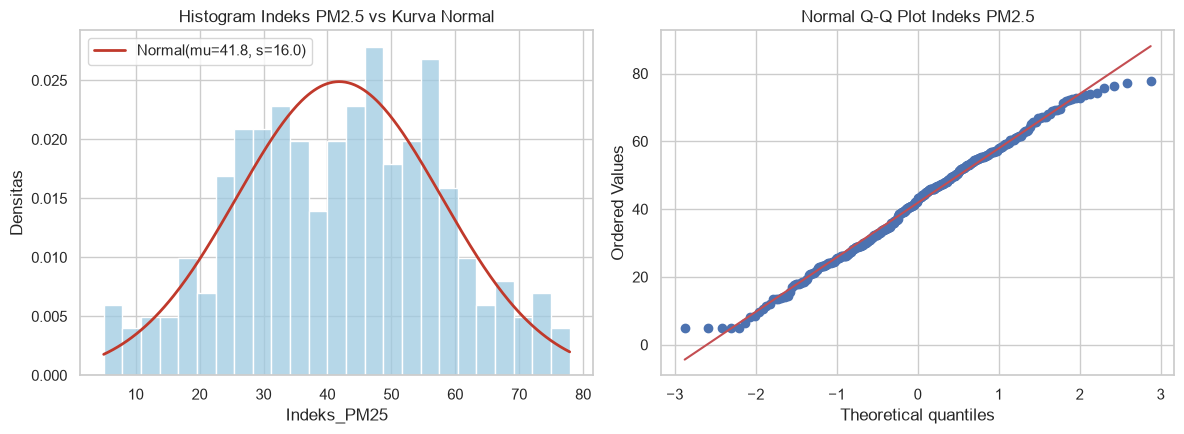

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Panel 1: Histogram + kurva PDF Normal
sns.histplot(x, bins=25, stat="density", color="#9ecae1", edgecolor="white", ax=axes[0])
grid = np.linspace(x.min(), x.max(), 300)
axes[0].plot(grid, stats.norm.pdf(grid, mu, sigma), color="#c0392b", lw=2,
             label=f"Normal(mu={mu:.1f}, s={sigma:.1f})")
axes[0].set_title("Histogram Indeks PM2.5 vs Kurva Normal")
axes[0].set_xlabel(VAR)
axes[0].set_ylabel("Densitas")
axes[0].legend()

# Panel 2: Q-Q Plot
stats.probplot(x, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q Plot Indeks PM2.5")

plt.tight_layout()
simpan_gambar(fig, "02_normal_histogram_qq")
plt.show()

In [8]:
baris = []
for k, teori in [(1, 68.27), (2, 95.45), (3, 99.73)]:
    aktual = ((x >= mu - k * sigma) & (x <= mu + k * sigma)).mean() * 100
    baris.append([f"mu +- {k}s", teori, round(aktual, 2), round(aktual - teori, 2)])

tabel_empiris = pd.DataFrame(baris, columns=["Rentang", "Teori_Normal_%", "Data_Aktual_%", "Selisih_%"])
simpan_tabel(tabel_empiris, "02_normal_aturan_empiris", index=False)
tabel_empiris

[tersimpan] outputs/tables/02_normal_aturan_empiris.csv


,Rentang,Teori_Normal_%,Data_Aktual_%,Selisih_%
0,mu +- 1s,68.27,67.25,-1.02
1,mu +- 2s,95.45,95.65,0.20
2,mu +- 3s,99.73,100.00,0.27


In [9]:
# Uji Shapiro-Wilk (H0: data berdistribusi normal)
w_stat, p_shapiro = stats.shapiro(x)
# Uji Kolmogorov-Smirnov satu sampel terhadap N(mu, sigma)
ks_stat, p_ks = stats.kstest(x, stats.norm.cdf, args=(mu, sigma))

print(f"Uji Shapiro-Wilk        : W = {w_stat:.4f}, p-value = {p_shapiro:.4g}")
print(f"Uji Kolmogorov-Smirnov  : D = {ks_stat:.4f}, p-value = {p_ks:.4g}")
keputusan_sw = (
    "Tolak H0 (sebaran data menyimpang dari normal sempurna)" if p_shapiro < ALPHA
    else "Gagal Tolak H0 (sebaran data sesuai dengan distribusi normal)"
)
print("Keputusan (alpha = 0.05):", keputusan_sw)

akt_1s = tabel_empiris.loc[0, "Data_Aktual_%"]
akt_2s = tabel_empiris.loc[1, "Data_Aktual_%"]
ket_visual = "menunjukkan sedikit deviasi pada bagian ekor distribusi" if p_shapiro < ALPHA else "mengikuti garis diagonal dengan cukup baik"

display(Markdown(f"""
### Interpretasi Kecocokan Distribusi Normal
Berdasarkan pemeriksaan parameter sampel pada variabel `Indeks_PM25`, diperoleh nilai rata-rata $\mu = {mu:.2f}$ dan simpangan baku $s = {sigma:.2f}$ dengan koefisien kemencengan (*skewness*) sebesar **{skew_val:.2f}**. 
Secara visual, tampilan histogram dan *Q-Q plot* memperlihatkan bahwa sebagian besar titik pengamatan **{ket_visual}**. 
Hasil pengujian formal Shapiro-Wilk menghasilkan nilai statistik $W = {w_stat:.4f}$ ($p\text{{-value}} = {p_shapiro:.4g}$). 
Mengingat uji kenormalan formal cenderung sensitif terhadap penyimpangan kecil pada ukuran sampel besar ($N = {N}$), evaluasi terhadap aturan empiris 68–95–99,7 menunjukkan proporsi cakupan data aktual pada rentang $\mu \pm 1s$ sebesar **{akt_1s:.2f}%** dan $\mu \pm 2s$ sebesar **{akt_2s:.2f}%**, sehingga model distribusi normal tetap layak digunakan sebagai pendekatan estimasi probabilitas.
"""))

Uji Shapiro-Wilk        : W = 0.9913, p-value = 0.04022
Uji Kolmogorov-Smirnov  : D = 0.0390, p-value = 0.6564
Keputusan (alpha = 0.05): Tolak H0 (sebaran data menyimpang dari normal sempurna)


<>:26: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:24: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:24: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:26: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:24: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:24: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\USER\AppData\Local\Temp\ipykernel_33700\1214255704.py:26: SyntaxWar


### Interpretasi Kecocokan Distribusi Normal
Berdasarkan pemeriksaan parameter sampel pada variabel `Indeks_PM25`, diperoleh nilai rata-rata $\mu = 41.85$ dan simpangan baku $s = 16.03$ dengan koefisien kemencengan (*skewness*) sebesar **-0.07**. 
Secara visual, tampilan histogram dan *Q-Q plot* memperlihatkan bahwa sebagian besar titik pengamatan **menunjukkan sedikit deviasi pada bagian ekor distribusi**. 
Hasil pengujian formal Shapiro-Wilk menghasilkan nilai statistik $W = 0.9913$ ($p	ext{-value} = 0.04022$). 
Mengingat uji kenormalan formal cenderung sensitif terhadap penyimpangan kecil pada ukuran sampel besar ($N = 345$), evaluasi terhadap aturan empiris 68–95–99,7 menunjukkan proporsi cakupan data aktual pada rentang $\mu \pm 1s$ sebesar **67.25%** dan $\mu \pm 2s$ sebesar **95.65%**, sehingga model distribusi normal tetap layak digunakan sebagai pendekatan estimasi probabilitas.


### B2. Simulasi Peluang pada Dua Skenario Batas
Nilai batas konsentrasi partikulat ditransformasikan ke dalam skor baku normal ($Z$) menggunakan persamaan:

$$Z = \frac{x - \mu}{s}$$

Dua skenario batas dievaluasi untuk membandingkan prediksi teoretis distribusi normal dengan proporsi aktual di lapangan:
* **Skenario 1:** $P(\text{Indeks\_PM25} > 65)$, merepresentasikan peluang terjadinya polusi tingkat tinggi (kategori *Tidak Sehat*).
* **Skenario 2:** $P(\text{Indeks\_PM25} \le 35)$, merepresentasikan peluang kondisi kualitas udara bersih (kategori *Baik*).

In [10]:
def peluang_normal(batas, arah):
    z = (batas - mu) / sigma
    if arah == "lebih_dari":
        p = 1 - stats.norm.cdf(z)
        emp = (x > batas).mean()
        teks = f"P(X > {batas})"
    else:
        p = stats.norm.cdf(z)
        emp = (x <= batas).mean()
        teks = f"P(X <= {batas})"
    return {
        "Skenario": teks,
        "Skor_Z": round(z, 3),
        "Peluang_Normal": round(p, 4),
        "Proporsi_Aktual": round(emp, 4),
        "Selisih": round(p - emp, 4)
    }

tabel_normal = pd.DataFrame([
    peluang_normal(65, "lebih_dari"),
    peluang_normal(35, "kurang_dari"),
])

simpan_tabel(tabel_normal, "02_normal_peluang", index=False)
tabel_normal

[tersimpan] outputs/tables/02_normal_peluang.csv


,Skenario,Skor_Z,Peluang_Normal,Proporsi_Aktual,Selisih
0,P(X > 65),1.445,0.0743,0.0783,-0.0040
1,P(X <= 35),-0.427,0.3347,0.3652,-0.0306


[tersimpan] outputs/figures/02_normal_area_peluang.png

<>:31: SyntaxWarning: "\_" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\_"? A raw string is also an option.
<>:31: SyntaxWarning: "\_" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\_"? A raw string is also an option.
<>:31: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:32: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:31: SyntaxWarning: "\_" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\_"? A raw string is also an option.
<>:31: SyntaxWarning: "\_" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\_"? A raw string is also an option.
<>:31: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences wil

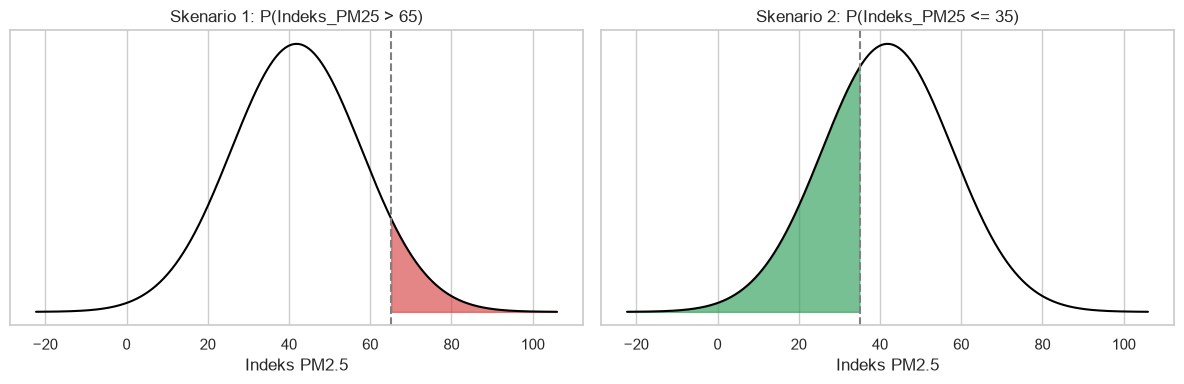


### Interpretasi Peluang Skenario Distribusi Normal
Hasil standardisasi skor-$Z$ pada skenario pertama menghasilkan nilai $Z = 1.445$, yang memberikan estimasi probabilitas teoretis $P(	ext{Indeks\_PM25} > 65)$ sebesar **0.0743** (**7.43%**), dibandingkan proporsi aktual pada dataset sebesar **0.0783** (**7.83%**). 
Pada skenario kedua, diperoleh skor $Z = -0.427$ dengan probabilitas teoretis $P(	ext{Indeks\_PM25} \le 35)$ sebesar **0.3347** (**33.47%**), sedangkan proporsi aktualnya tercatat sebesar **0.3652** (**36.52%**). 
Selisih antara estimasi model normal dan proporsi empiris terjadi karena variabel konsentrasi polutan memiliki batas bawah nol (*non-negative*) serta sedikit kemencengan distribusi (*skewness*), sementara kurva normal teoretis bersifat simetris dari $-\infty$ hingga $+\infty$.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
grid = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 400)
pdf = stats.norm.pdf(grid, mu, sigma)

axes[0].plot(grid, pdf, color="black", lw=1.5)
axes[0].fill_between(grid, pdf, where=grid > 65, color="#d64545", alpha=0.65)
axes[0].axvline(65, ls="--", color="gray")
axes[0].set_title("Skenario 1: P(Indeks_PM25 > 65)")

axes[1].plot(grid, pdf, color="black", lw=1.5)
axes[1].fill_between(grid, pdf, where=grid <= 35, color="#2e9e5b", alpha=0.65)
axes[1].axvline(35, ls="--", color="gray")
axes[1].set_title("Skenario 2: P(Indeks_PM25 <= 35)")

for a in axes:
    a.set_xlabel("Indeks PM2.5")
    a.set_yticks([])

plt.tight_layout()
simpan_gambar(fig, "02_normal_area_peluang")
plt.show()

z1, p1_norm, p1_akt = tabel_normal.loc[0, ["Skor_Z", "Peluang_Normal", "Proporsi_Aktual"]]
z2, p2_norm, p2_akt = tabel_normal.loc[1, ["Skor_Z", "Peluang_Normal", "Proporsi_Aktual"]]

display(Markdown(f"""
### Interpretasi Peluang Skenario Distribusi Normal
Hasil standardisasi skor-$Z$ pada skenario pertama menghasilkan nilai $Z = {z1:.3f}$, yang memberikan estimasi probabilitas teoretis $P(\text{{Indeks\_PM25}} > 65)$ sebesar **{p1_norm:.4f}** (**{p1_norm*100:.2f}%**), dibandingkan proporsi aktual pada dataset sebesar **{p1_akt:.4f}** (**{p1_akt*100:.2f}%**). 
Pada skenario kedua, diperoleh skor $Z = {z2:.3f}$ dengan probabilitas teoretis $P(\text{{Indeks\_PM25}} \le 35)$ sebesar **{p2_norm:.4f}** (**{p2_norm*100:.2f}%**), sedangkan proporsi aktualnya tercatat sebesar **{p2_akt:.4f}** (**{p2_akt*100:.2f}%**). 
Selisih antara estimasi model normal dan proporsi empiris terjadi karena variabel konsentrasi polutan memiliki batas bawah nol (*non-negative*) serta sedikit kemencengan distribusi (*skewness*), sementara kurva normal teoretis bersifat simetris dari $-\infty$ hingga $+\infty$.
"""))

## C. Pemodelan Distribusi Binomial (Tahap 2c)

Pemodelan diskrit dilakukan menggunakan **Distribusi Binomial** $X \sim \text{Binomial}(n, p)$ untuk menyimulasikan pengambilan sampel acak sebanyak $n = 20$ titik pengukuran kualitas udara. Peubah acak $X$ menyatakan banyaknya titik pengamatan yang tercatat berstatus **Tidak Sehat** ("kejadian sukses" secara statistik), dengan fungsi massa probabilitas (*PMF*):

$$P(X = k) = \binom{n}{k} p^k (1 - p)^{n - k}, \quad k = 0, 1, 2, \dots, 20$$

Parameter peluang keberhasilan $p$ diestimasi dari proporsi empiris kejadian `Status_Udara == "Tidak Sehat"` pada dataset bersih.

In [12]:
# Variabel biner: 1 jika Status_Udara == 'Tidak Sehat', 0 jika lainnya
sukses = (df["Status_Udara"].astype(str).str.strip() == "Tidak Sehat")
p = sukses.mean()
n = 20

print(f"Proporsi sukses empiris (p) = {sukses.sum()} / {N} = {p:.4f}")
print(f"Ekspektasi E(X) = n * p     = {n * p:.2f} titik Tidak Sehat dari {n} titik")
print(f"Simpangan baku SD(X)        = {np.sqrt(n * p * (1 - p)):.2f}")

Proporsi sukses empiris (p) = 27 / 345 = 0.0783
Ekspektasi E(X) = n * p     = 1.57 titik Tidak Sehat dari 20 titik
Simpangan baku SD(X)        = 1.20


In [13]:
k = np.arange(0, n + 1)
tabel_binom = pd.DataFrame({
    "k": k,
    "P(X = k)": stats.binom.pmf(k, n, p),
    "P(X <= k)": stats.binom.cdf(k, n, p),
    "P(X >= k)": stats.binom.sf(k - 1, n, p)
}).round(4)

simpan_tabel(tabel_binom, "02_binomial_tabel", index=False)
tabel_binom.head(12)

[tersimpan] outputs/tables/02_binomial_tabel.csv


,k,P(X = k),P(X <= k),P(X >= k)
0,0,0.1960,0.1960,1.0000
1,1,0.3328,0.5287,0.8040
2,2,0.2684,0.7971,0.4713
3,3,0.1367,0.9339,0.2029
4,4,0.0493,0.9832,0.0661
5,5,0.0134,0.9966,0.0168
6,6,0.0028,0.9994,0.0034
7,7,0.0005,0.9999,0.0006
8,8,0.0001,1.0000,0.0001
9,9,0.0000,1.0000,0.0000


P(X = 4)  = 0.0493 (4.93%)
P(X >= 5) = 0.0168 (1.68%)


<>:29: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:29: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
C:\Users\USER\AppData\Local\Temp\ipykernel_33700\3926893576.py:29: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
  """))


[tersimpan] outputs/figures/02_binomial_pmf.png


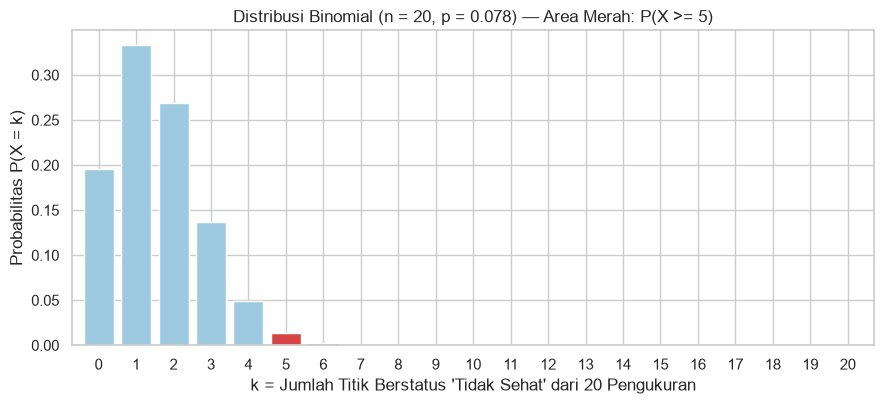


### Interpretasi Hasil Pemodelan Distribusi Binomial
Dengan proporsi empiris kejadian kualitas udara Tidak Sehat sebesar $p = 0.0783$, pengambilan $n = 20$ titik pemantauan secara acak memiliki nilai harapan sebesar $E(X) = 1.57$ titik yang berada dalam kondisi Tidak Sehat. 
Berdasarkan hasil perhitungan fungsi massa probabilitas, peluang ditemukan tepat $k = 4$ titik berstatus Tidak Sehat adalah $P(X = 4) = 0.0493$ (**4.93%**), sementara peluang kumulatif ditemukan paling sedikit $k = 5$ titik berstatus Tidak Sehat mencapai $P(X \ge 5) = 0.0168$ (**1.68%**). 
Sebagai batasan metodologis, penerapan distribusi binomial di sini bersifat pendekatan karena pada kondisi lapangan peluang terjadinya polusi antar-titik lokasi dan waktu pengamatan dapat bervariasi serta tidak sepenuhnya saling bebas.


In [14]:
# Nilai k disesuaikan dengan skenario risiko yang dievaluasi tim
K_TEPAT = 4
K_MINIMAL = 5

p_tepat = stats.binom.pmf(K_TEPAT, n, p)
p_minimal = stats.binom.sf(K_MINIMAL - 1, n, p)

print(f"P(X = {K_TEPAT})  = {p_tepat:.4f} ({p_tepat*100:.2f}%)")
print(f"P(X >= {K_MINIMAL}) = {p_minimal:.4f} ({p_minimal*100:.2f}%)")

fig, ax = plt.subplots(figsize=(9, 4.2))
warna = ["#d64545" if i >= K_MINIMAL else "#9ecae1" for i in k]
ax.bar(k, stats.binom.pmf(k, n, p), color=warna, edgecolor="white")
ax.set_xlabel("k = Jumlah Titik Berstatus 'Tidak Sehat' dari 20 Pengukuran")
ax.set_ylabel("Probabilitas P(X = k)")
ax.set_title(f"Distribusi Binomial (n = 20, p = {p:.3f}) — Area Merah: P(X >= {K_MINIMAL})")
ax.set_xticks(range(0, 21))
ax.set_xlim(-0.7, 20.7)

plt.tight_layout()
simpan_gambar(fig, "02_binomial_pmf")
plt.show()

display(Markdown(f"""
### Interpretasi Hasil Pemodelan Distribusi Binomial
Dengan proporsi empiris kejadian kualitas udara Tidak Sehat sebesar $p = {p:.4f}$, pengambilan $n = 20$ titik pemantauan secara acak memiliki nilai harapan sebesar $E(X) = {n*p:.2f}$ titik yang berada dalam kondisi Tidak Sehat. 
Berdasarkan hasil perhitungan fungsi massa probabilitas, peluang ditemukan tepat $k = {K_TEPAT}$ titik berstatus Tidak Sehat adalah $P(X = {K_TEPAT}) = {p_tepat:.4f}$ (**{p_tepat*100:.2f}%**), sementara peluang kumulatif ditemukan paling sedikit $k = {K_MINIMAL}$ titik berstatus Tidak Sehat mencapai $P(X \ge {K_MINIMAL}) = {p_minimal:.4f}$ (**{p_minimal*100:.2f}%**). 
Sebagai batasan metodologis, penerapan distribusi binomial di sini bersifat pendekatan karena pada kondisi lapangan peluang terjadinya polusi antar-titik lokasi dan waktu pengamatan dapat bervariasi serta tidak sepenuhnya saling bebas.
"""))

## Serahkan hasil
Jalankan sel di bawah -> unduh ZIP -> upload ke GitHub (panduan: `docs/02_panduan_github_colab.md`).

In [15]:
# Opsional: mengemas seluruh output tahap 02a menjadi arsip ZIP jika diperlukan
unduh_hasil("hasil_02a_probability")

7 file dimasukkan ke hasil_02a_probability.zip:
  - outputs/tables/02a_peluang_empiris_bersyarat.csv
  - outputs/figures/02_normal_histogram_qq.png
  - outputs/tables/02_normal_aturan_empiris.csv
  - outputs/tables/02_normal_peluang.csv
  - outputs/figures/02_normal_area_peluang.png
  - outputs/tables/02_binomial_tabel.csv
  - outputs/figures/02_binomial_pmf.png
(bukan di Colab - ZIP ada di folder kerja)


'hasil_02a_probability.zip'

### Checklist Penyelesaian Tahap 2 (Minggu 2)
- [x] Perhitungan minimal 3 peluang empiris dan 2 peluang bersyarat beserta interpretasi (Checklist 2a)
- [x] Evaluasi kecocokan Distribusi Normal pada `Indeks_PM25` melalui histogram, Q-Q plot, aturan empiris, dan uji formal (Checklist 2b)
- [x] Perhitungan probabilitas skor-$Z$ pada 2 skenario batas beserta visualisasi area kurva (Checklist 2b)
- [x] Pemodelan Distribusi Binomial ($n = 20$) untuk nilai $P(X = k)$ dan $P(X \ge k)$ beserta grafik PMF (Checklist 2c)
- [x] Seluruh tabel dan grafik tersimpan di direktori `outputs/tables/` dan `outputs/figures/`